---
# Executed by scripts/export_gw_examples.py; the docs build shows the stored outputs.
execute:
  skip: true
---
# 1. A mock gravitational-wave catalog

This page was generated from [`notebooks/gw/01_gw_mock_catalog.py`](https://github.com/Potatoasad/astroinfer/blob/main/notebooks/gw/01_gw_mock_catalog.py), a marimo notebook. Sliders and other controls are shown at their default values. To change them, run the notebook with `uv run marimo edit notebooks/gw/01_gw_mock_catalog.py`.

This notebook builds the mock catalog that notebook 2 fits with TGMMs. It goes through these
steps in order:

1. a GWMockCat-style measurement process $\mathcal{L}(d\mid\theta)$ with effective spins;
2. a detection trigger $P(\mathrm{det}\mid d)$;
3. true source parameters $\theta_i \sim \pi(\theta\mid\Lambda_\mathrm{true})$, drawn from a
   structured distribution over `GWParams`;
4. simulated data $d_i \sim \mathcal{L}(d\mid\theta_i)$, of which only the detected events are kept;
5. parameter estimation for each detected event, with the posteriors collected in a `Catalog`
   and saved.

In [1]:
import sys
from pathlib import Path

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts" / "marimo_docs_shim.py").is_file())
sys.path[:0] = [str(ROOT / "notebooks/gw"), str(ROOT / "scripts")]

import marimo_docs_shim
marimo_docs_shim.set_notebook_dir(ROOT / "notebooks/gw")
sys.modules["marimo"] = marimo_docs_shim

# marimo shows a figure only when a cell returns it. Stop Jupyter from also showing every
# figure a cell creates, and close them once the cell has run.
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import flush_figures
get_ipython().run_line_magic("matplotlib", "inline")
try:
    get_ipython().events.unregister("post_execute", flush_figures)
except ValueError:
    pass
get_ipython().events.register("post_execute", lambda: plt.close("all"))

# Show astroinfer objects with their HTML display (as Jupyter does), not the short markdown one.
get_ipython().display_formatter.formatters["text/markdown"].enabled = False
# Open every object display, so readers see the contents without having to click.
import astroinfer.display
astroinfer.display.set_options(expanded=True)


In [2]:
import jax

jax.config.update("jax_enable_x64", True)

from pathlib import Path

import astroinfer as ai
import marimo as mo
import numpy as np
import numpyro.distributions as dist
import pandas as pd
import plot_helper as ph
from astroinfer import Catalog, RawSamples, parameter, parameter_dataclass
from astroinfer.detection import ThresholdTrigger

from astroinfer_gw.gwmockcat import GWMockCatMeasurement, GWParams, ToyOptimalSNR
from astroinfer_gw.physics import isotropic_projection_factor
from astroinfer_gw.populations import PowerLaw, PowerLawRedshift, ProjectionFactor

ph.restore_plot_defaults()
ph.set_plot_defaults(latex_font_size=16, usetex=True)

# The notebook's own folder (mo.notebook_dir() is the cwd when run as a script).
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path(mo.notebook_dir())
DATA_DIR = NOTEBOOK_DIR.parent / "data"
CATALOG_DIR = DATA_DIR / "gw_catalog"

N_TRUTHS = 20_000     # population draws to simulate
SNR_THRESHOLD = 4.0   # detected if the observed SNR exceeds this
N_EVENTS = 20         # detected events to run PE on

M_MIN, M_MAX = 5.0, 80.0   # primary mass range of the population, in solar masses
Z_MAX = 1.5                # largest redshift

LABELS = dict(mass_1_source=r"$m_1$", mass_ratio=r"$q$", redshift=r"$z$",
              chi_1=r"$\chi_1$", chi_2=r"$\chi_2$", cos_tilt_1=r"$\cos\theta_1$",
              cos_tilt_2=r"$\cos\theta_2$", chi_eff=r"$\chi_\mathrm{eff}$", chi_p=r"$\chi_p$",
              projection_factor=r"$\Theta$")

def as_table(theta):
    """A parameter object with one batch axis as a DataFrame, one column per field."""
    return pd.DataFrame({k: np.asarray(v) for k, v in theta.to_dict().items()})

## The measurement process and the trigger

The measurement process uses a toy model of the optimal SNR. An event is detected when its
observed SNR is above 4. Expanding the displays below shows the measurement's noise model and
the trigger's detection rule.

In [3]:
measurement = GWMockCatMeasurement(
    snr_model=ToyOptimalSNR(bns_horizon=300.0, reference_snr=8.0, reference_chirp_mass=1.2, m_cut=250.0)
)
trigger = ThresholdTrigger(SNR_THRESHOLD, statistic="snr")
mo.vstack([measurement, trigger])

snr_model,"ToyOptimalSNR(bns_horizon=300.0, reference_snr=8.0, m_cut=250.0)"
cosmology,RedshiftToLuminosityDistance(z_max=5.0)
u_chirp_mass,0.08
u_eta,0.022
u_projection,0.21
u_chi_eff,0.8
u_chi_p,7.2
snr_floor,1.0
sampler_kwargs,"{'num_warmup': 1000, 'num_samples': 8000, 'summary': False, 'sampler_kwargs': {'dense_mass': True}}"


statistic,snr
threshold,4.0


## The true population

The population is a structured distribution over `GWParams`, written one field at a time with
`GWParams.distribution(...)`. Its hyperparameters $\Lambda$ are a parameter dataclass,
`GWHyper`, which `.given(GWHyper)` declares as the distribution's condition. A field written
as a function receives the hyperparameters as `L`, and a field written as a distribution has
no hyperparameters. The fields are:

- $p(m_1) \propto m_1^{\alpha}$ between $m_\mathrm{min} = 5\,M_\odot$ and
  $m_\mathrm{max} = 80\,M_\odot$;
- $p(q \mid m_1) \propto q^{\beta}$ between $m_\mathrm{min}/m_1$ and 1, so that the secondary
  mass is at least $m_\mathrm{min}$. This is a conditional field, which reads the value of
  $m_1$ drawn before it;
- $p(z) \propto \frac{dV_c}{dz}(1+z)^{\lambda-1}$ up to $z = 1.5$;
- the isotropic projection factor $\Theta\sim\mathrm{Beta}(2,4)$;
- truncated normals for the spin magnitudes $\chi_1, \chi_2$ on $[0,1]$ and the tilt cosines
  $\cos\theta_1, \cos\theta_2$ on $[-1,1]$, each with its own mean and width.

`PowerLaw`, `PowerLawRedshift` and `ProjectionFactor` are NumPyro distributions from
`astroinfer_gw.populations`. `ProjectionFactor()` is $\mathrm{Beta}(2,4)$ with a polynomial
CDF, which is cheaper to invert when the population is converted with `as_generative`, as in
notebook 3. The lower bound of $q$ depends on $m_1$, so its `PowerLaw` is given the fixed
support $[0, 1]$ for that conversion; the density is zero below $m_\mathrm{min}/m_1$. Neither
power law is smoothed, so the mass distribution has a sharp edge at $m_\mathrm{min}$.

In [4]:
@parameter_dataclass(name="GW population hyperparameters", latex=r"\Lambda")
class GWHyper:
    alpha: float = parameter(name="Primary mass slope", latex=r"\alpha")
    beta: float = parameter(name="Mass ratio slope", latex=r"\beta")
    lamb: float = parameter(name="Redshift evolution", latex=r"\lambda")
    mu_chi_1: float = parameter(name="Mean primary spin magnitude", latex=r"\mu_{\chi_1}")
    sigma_chi_1: float = parameter(name="Width of primary spin magnitudes", latex=r"\sigma_{\chi_1}")
    mu_chi_2: float = parameter(name="Mean secondary spin magnitude", latex=r"\mu_{\chi_2}")
    sigma_chi_2: float = parameter(name="Width of secondary spin magnitudes", latex=r"\sigma_{\chi_2}")
    mu_cos_tilt_1: float = parameter(name="Mean primary tilt cosine", latex=r"\mu_{t_1}")
    sigma_cos_tilt_1: float = parameter(name="Width of primary tilt cosines", latex=r"\sigma_{t_1}")
    mu_cos_tilt_2: float = parameter(name="Mean secondary tilt cosine", latex=r"\mu_{t_2}")
    sigma_cos_tilt_2: float = parameter(name="Width of secondary tilt cosines", latex=r"\sigma_{t_2}")

population = GWParams.distribution(
    mass_1_source=lambda L: PowerLaw(L.alpha, M_MIN, M_MAX),
    mass_ratio=ai.conditional(
        lambda x, L: PowerLaw(L.beta, M_MIN / x["mass_1_source"], 1.0, support=(0.0, 1.0)),
        on="mass_1_source"),
    redshift=lambda L: PowerLawRedshift(L.lamb, z_max=Z_MAX),
    projection_factor=ProjectionFactor(),
    chi_1=lambda L: dist.TruncatedNormal(L.mu_chi_1, L.sigma_chi_1, low=0.0, high=1.0),
    chi_2=lambda L: dist.TruncatedNormal(L.mu_chi_2, L.sigma_chi_2, low=0.0, high=1.0),
    cos_tilt_1=lambda L: dist.TruncatedNormal(L.mu_cos_tilt_1, L.sigma_cos_tilt_1, low=-1.0, high=1.0),
    cos_tilt_2=lambda L: dist.TruncatedNormal(L.mu_cos_tilt_2, L.sigma_cos_tilt_2, low=-1.0, high=1.0),
).given(GWHyper)

Lambda_true = GWHyper(alpha=-2.35, beta=1.1, lamb=2.7,
                      mu_chi_1=0.4, sigma_chi_1=0.05, mu_chi_2=0.0, sigma_chi_2=0.05,
                      mu_cos_tilt_1=0.8, sigma_cos_tilt_1=0.1, mu_cos_tilt_2=0.8, sigma_cos_tilt_2=0.1)
mo.vstack([population, Lambda_true])

order,"mass_1_source, mass_ratio, redshift, projection_factor, chi_1, chi_2, cos_tilt_1, cos_tilt_2"


GWHyper(batch_shape=(), alpha=(), beta=(), lamb=(), mu_chi_1=(), sigma_chi_1=(), mu_chi_2=(), sigma_chi_2=(), mu_cos_tilt_1=(), sigma_cos_tilt_1=(), mu_cos_tilt_2=(), sigma_cos_tilt_2=())

## Simulating detections

`population.sample(Lambda, key=..., N=...)` returns the true parameters as a `GWParams` with
batch shape `(N,)`. `measurement.sample` takes them directly and returns the simulated data as
a batched `GWMockCatData`. `trigger.detect` returns a boolean mask of the detected events,
which can index both the true parameters and the data:

In [5]:
truths = population.sample(Lambda_true, key=1, N=N_TRUTHS)
data = measurement.sample(truths, key=jax.random.key(2))
detected = trigger.detect(data, np.random.default_rng(3))

detected_truths = truths[detected]
detected_data = data[detected]

mo.md(f"{detected.sum()} of {N_TRUTHS:,} simulated sources are detected "
      f"(observed SNR > {SNR_THRESHOLD:g}).")

For plots and for the catalog metadata, `measurement.with_derived` turns the true parameters
into a table with the derived parameters ($\chi_\mathrm{eff}$, $\chi_p$, the detector-frame
chirp mass, $d_L$ and $m_2$) added as columns:

In [6]:
truth_table = measurement.with_derived(as_table(truths))
detected_table = truth_table[np.asarray(detected)].reset_index(drop=True)
detected_table.head()

,mass_1_source,mass_ratio,redshift,projection_factor,chi_1,chi_2,cos_tilt_1,cos_tilt_2,mass_2_source,chirp_mass_det,luminosity_distance,chi_eff,chi_p
0,22.917132,0.563459,1.491086,0.640937,0.398446,0.011792,0.613013,0.828259,12.912872,37.004040,11115.759484,0.159745,0.314801
1,23.641276,0.974041,1.025887,0.569150,0.397867,0.065781,0.892263,0.799057,23.027568,41.149179,7009.228100,0.205771,0.179643
2,9.828546,0.663083,0.687403,0.469286,0.469435,0.103472,0.810285,0.806604,6.517138,11.707546,4287.723338,0.261994,0.275106
3,14.606935,0.806537,0.283370,0.730962,0.387451,0.010322,0.720818,0.886580,11.781037,14.639163,1499.807215,0.158681,0.268552
4,44.605905,0.480705,0.942422,0.473618,0.463300,0.073757,0.878193,0.681532,21.442272,51.614204,6313.229273,0.291098,0.221600


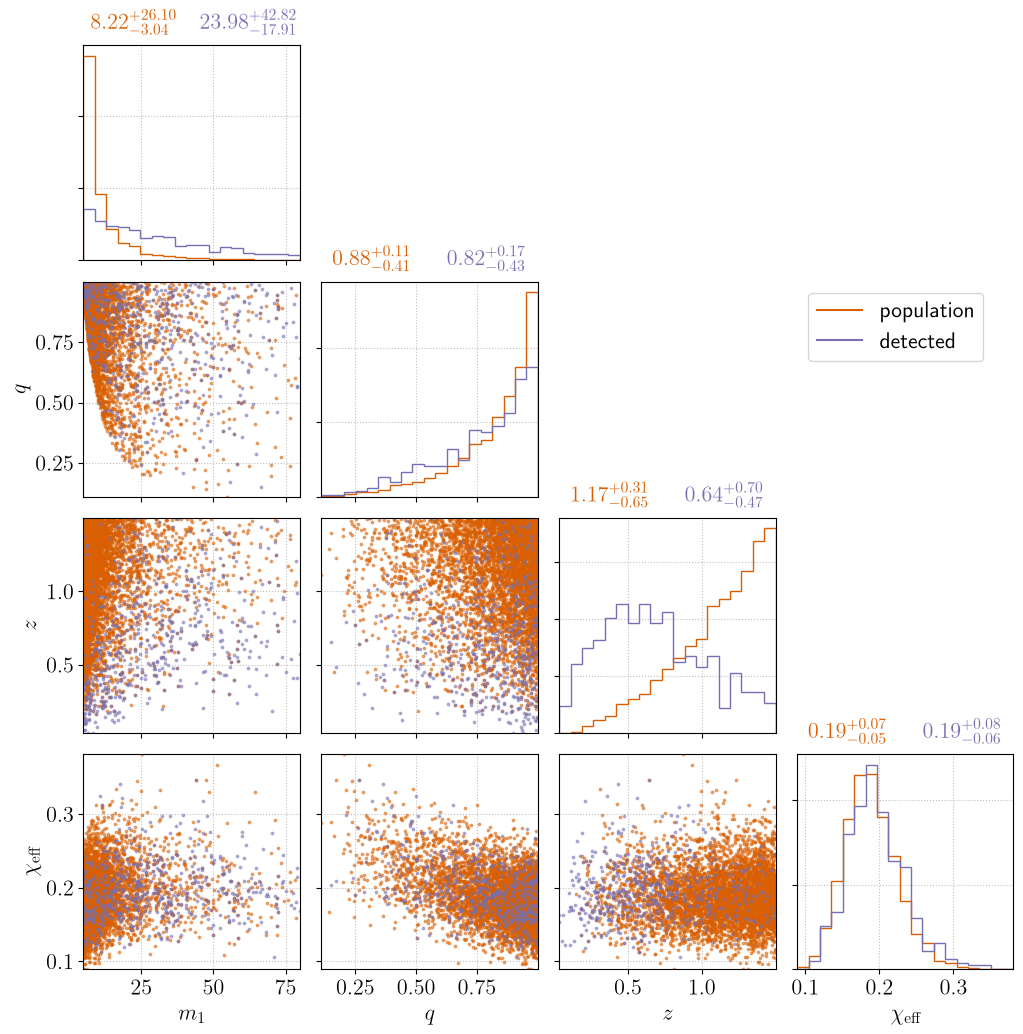

In [7]:
_variables = ["mass_1_source", "mass_ratio", "redshift", "chi_eff"]
_fig, _ = ph.make_corner_plot(
    [truth_table.sample(5000, random_state=0)[_variables], detected_table[_variables]],
    model_labels=["population", "detected"], variables=_variables,
    variable_labels=[LABELS[v] for v in _variables], scatter_kwargs=dict(s=3, alpha=0.5))
_fig

In [8]:
observed = as_table(detected_data)
observed.head(N_EVENTS)

,snr,log_chirp_mass_det,symmetric_mass_ratio,projection_factor_obs,chi_eff,chi_p
0,5.400490,3.620473,0.235335,0.632699,0.239157,0.644435
1,5.120143,3.682543,0.245828,0.568237,0.160837,0.747459
2,4.104225,2.475365,0.238479,0.495381,0.047686,0.292185
3,10.850069,2.685029,0.244815,0.728035,0.111918,0.648604
4,4.055092,3.946790,0.223720,0.512079,0.282855,0.114033
5,8.051496,3.980834,0.222408,0.631307,0.105598,0.252069
6,6.175663,2.612664,0.246276,0.574979,0.211892,0.484644
7,5.000260,1.979788,0.247425,0.342677,0.058619,0.703176
8,4.206002,3.500690,0.241925,0.819119,0.170284,0.375405
9,4.818670,4.403044,0.245227,0.363970,0.141669,0.988460


## Parameter estimation

The PE priors are uniform in $m_1$, $q$, $z$ and the spins, and isotropic in $\Theta$.
`measurement.PE(d, priors, as_posterior=True)` runs NUTS on $\mathcal{L}(d\mid\theta)$ and returns a
`PosteriorData`. It holds the draws of $\theta$ as a `GWParams`, the derived parameters, the PE
prior density as `prior`, and the log prior of each parameter as `log_prior[...]`. The catalog
and the TGMM fits use these per-parameter factors to compute the prior of only the columns they
export.

PE takes a few seconds per event. The catalog is saved to `notebooks/data/gw_catalog`. If that
folder already holds a catalog of the same events, with the true parameters simulated above in
its metadata, it is loaded instead, unless you tick the box. A saved catalog of other events,
left over from a different population or seed, is replaced.

In [9]:
pe_priors = dict(
    mass_1_source=dist.Uniform(2.0, 120.0), mass_ratio=dist.Uniform(0.05, 1.0),
    redshift=dist.Uniform(0.0, 1.5), projection_factor=isotropic_projection_factor(),
    chi_1=dist.Uniform(0.0, 1.0), chi_2=dist.Uniform(0.0, 1.0),
    cos_tilt_1=dist.Uniform(-1.0, 1.0), cos_tilt_2=dist.Uniform(-1.0, 1.0))
force_pe = mo.ui.checkbox(label="re-run PE (overwrites notebooks/data/gw_catalog)")
force_pe

In [10]:
_n = min(N_EVENTS, len(detected_table))

def _same_events(saved):
    """Whether a saved catalog holds PE for the first _n detected events simulated above."""
    if len(saved.eventnames) != _n:
        return False
    stored = [saved.posterior(name).metadata["injected_true"] for name in saved.eventnames]
    return all(np.isclose(row[k], detected_table.iloc[i][k])
               for i, row in enumerate(stored) for k in GWParams.field_specs())

catalog = Catalog.load(CATALOG_DIR) if CATALOG_DIR.exists() and not force_pe.value else None
if catalog is None or not _same_events(catalog):
    catalog = Catalog(raw=RawSamples(columns=["mass_1_source", "mass_ratio", "chi_1", "chi_2", "cos_tilt_1", "cos_tilt_2", "redshift"], N=2000))
    for _i in mo.status.progress_bar(range(_n), title="Parameter estimation"):
        _posterior = measurement.PE(detected_data[_i], pe_priors, seed=_i, as_posterior=True,
                                    num_warmup=500, num_samples=4000)
        catalog.add_event(f"event_{_i + 1:02d}", _posterior,
                          metadata={"injected_true": detected_table.iloc[_i].to_dict()})
    catalog.save(CATALOG_DIR)
catalog

[juliapkg] Found dependencies: /Users/ahussain/Documents/GitHub/astroinfer/.venv/lib/python3.12/site-packages/juliapkg/juliapkg.json
[juliapkg] Found dependencies: /Users/ahussain/Documents/GitHub/astroinfer/.venv/lib/python3.12/site-packages/juliacall/juliapkg.json
[juliapkg] Found dependencies: /Users/ahussain/.cache/uv/builds-v0/.tmp5BUCEI/julia_env/pyjuliapkg/juliapkg.json
[juliapkg] Found dependencies: /Users/ahussain/Documents/GitHub/astroinfer/.venv/lib/python3.12/site-packages/truncatedgaussianmixtures/juliapkg.json
[juliapkg] Locating Julia 1.10.3 - 1.11
[juliapkg] Querying Julia versions from https://julialang-s3.julialang.org/bin/versions.json


[juliapkg] WARNING: About to install Julia 1.11.9 to /Users/ahussain/.cache/uv/builds-v0/.tmp5BUCEI/julia_env/pyjuliapkg/install.
[juliapkg]   If you use juliapkg in more than one environment, you are likely to
[juliapkg]   have Julia installed in multiple locations. It is recommended to
[juliapkg]   install JuliaUp (https://github.com/JuliaLang/juliaup) or Julia
[juliapkg]   (https://julialang.org/downloads) yourself.
[juliapkg] Downloading Julia from https://julialang-s3.julialang.org/bin/mac/aarch64/1.11/julia-1.11.9-macaarch64.dmg


             downloaded 19.1 MB of 225.3 MB


             downloaded 39.6 MB of 225.3 MB


             downloaded 62.4 MB of 225.3 MB


             downloaded 88.5 MB of 225.3 MB


... (7 outputs left out)

[juliapkg] Using Julia project at /Users/ahussain/.cache/uv/builds-v0/.tmp5BUCEI/julia_env
[juliapkg] Writing Project.toml:
           | [deps]
           | PythonCall = "6099a3de-0909-46bc-b1f4-468b9a2dfc0d"
           | OpenSSL_jll = "458c3c95-2e84-50aa-8efc-19380b2a3a95"
           | TruncatedGaussianMixtures = "d6a30cd5-d352-42fd-9418-e34000539a5a"
           | DataFrames = "a93c6f00-e57d-5684-b7b6-d8193f3e46c0"
           | Distributions = "31c24e10-a181-5473-b8eb-7969acd0382f"
           | LinearAlgebra = "37e2e46d-f89d-539d-b4ee-838fcccc9c8e"
           | StatsBase = "2913bbd2-ae8a-5f71-8c99-4fb6c76f3a91"
           | 
           | [compat]
           | PythonCall = "=0.9.37"
           | OpenSSL_jll = "~3.0"
           | 
           | [preferences]
[juliapkg] Installing packages:
           | import Pkg
           | Pkg.Registry.update()
           | Pkg.add([
           |   Pkg.PackageSpec(name="PythonCall", uuid="6099a3de-0909-46bc-b1f4-468b9a2dfc0d"),
           |   Pkg.Pack

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


Detected Jupyter notebook. Loading juliacall extension. Set `PYSR_AUTOLOAD_EXTENSIONS=no` to disable.


Catalog(n_events=20, columns=['mass_1_source', 'mass_ratio', 'chi_1', 'chi_2', 'cos_tilt_1', 'cos_tilt_2', 'redshift'], representations=['raw', 'masses', 'spins', 'masses_log'])

## One event's posterior

The plot marks the event's true parameters, which were stored in its metadata when it was added
to the catalog.

In [11]:
event = mo.ui.dropdown(catalog.eventnames, value=catalog.eventnames[0], label="event")
event

PosteriorData[GWParams](sizes={'draw': 4000}, sample_stats=['accept_prob', 'adapt_state.step_size', 'chain', 'diverging', 'energy', 'log_likelihood', 'log_prior[chi_1]', 'log_prior[chi_2]', 'log_prior[cos_tilt_1]', 'log_prior[cos_tilt_2]', 'log_prior[mass_1_source]', 'log_prior[mass_ratio]', 'log_prior[projection_factor]', 'log_prior[redshift]', 'num_steps', 'potential_energy', 'prior'], extras=['chi_eff', 'chi_p', 'chirp_mass_det', 'luminosity_distance', 'mass_2_source'])

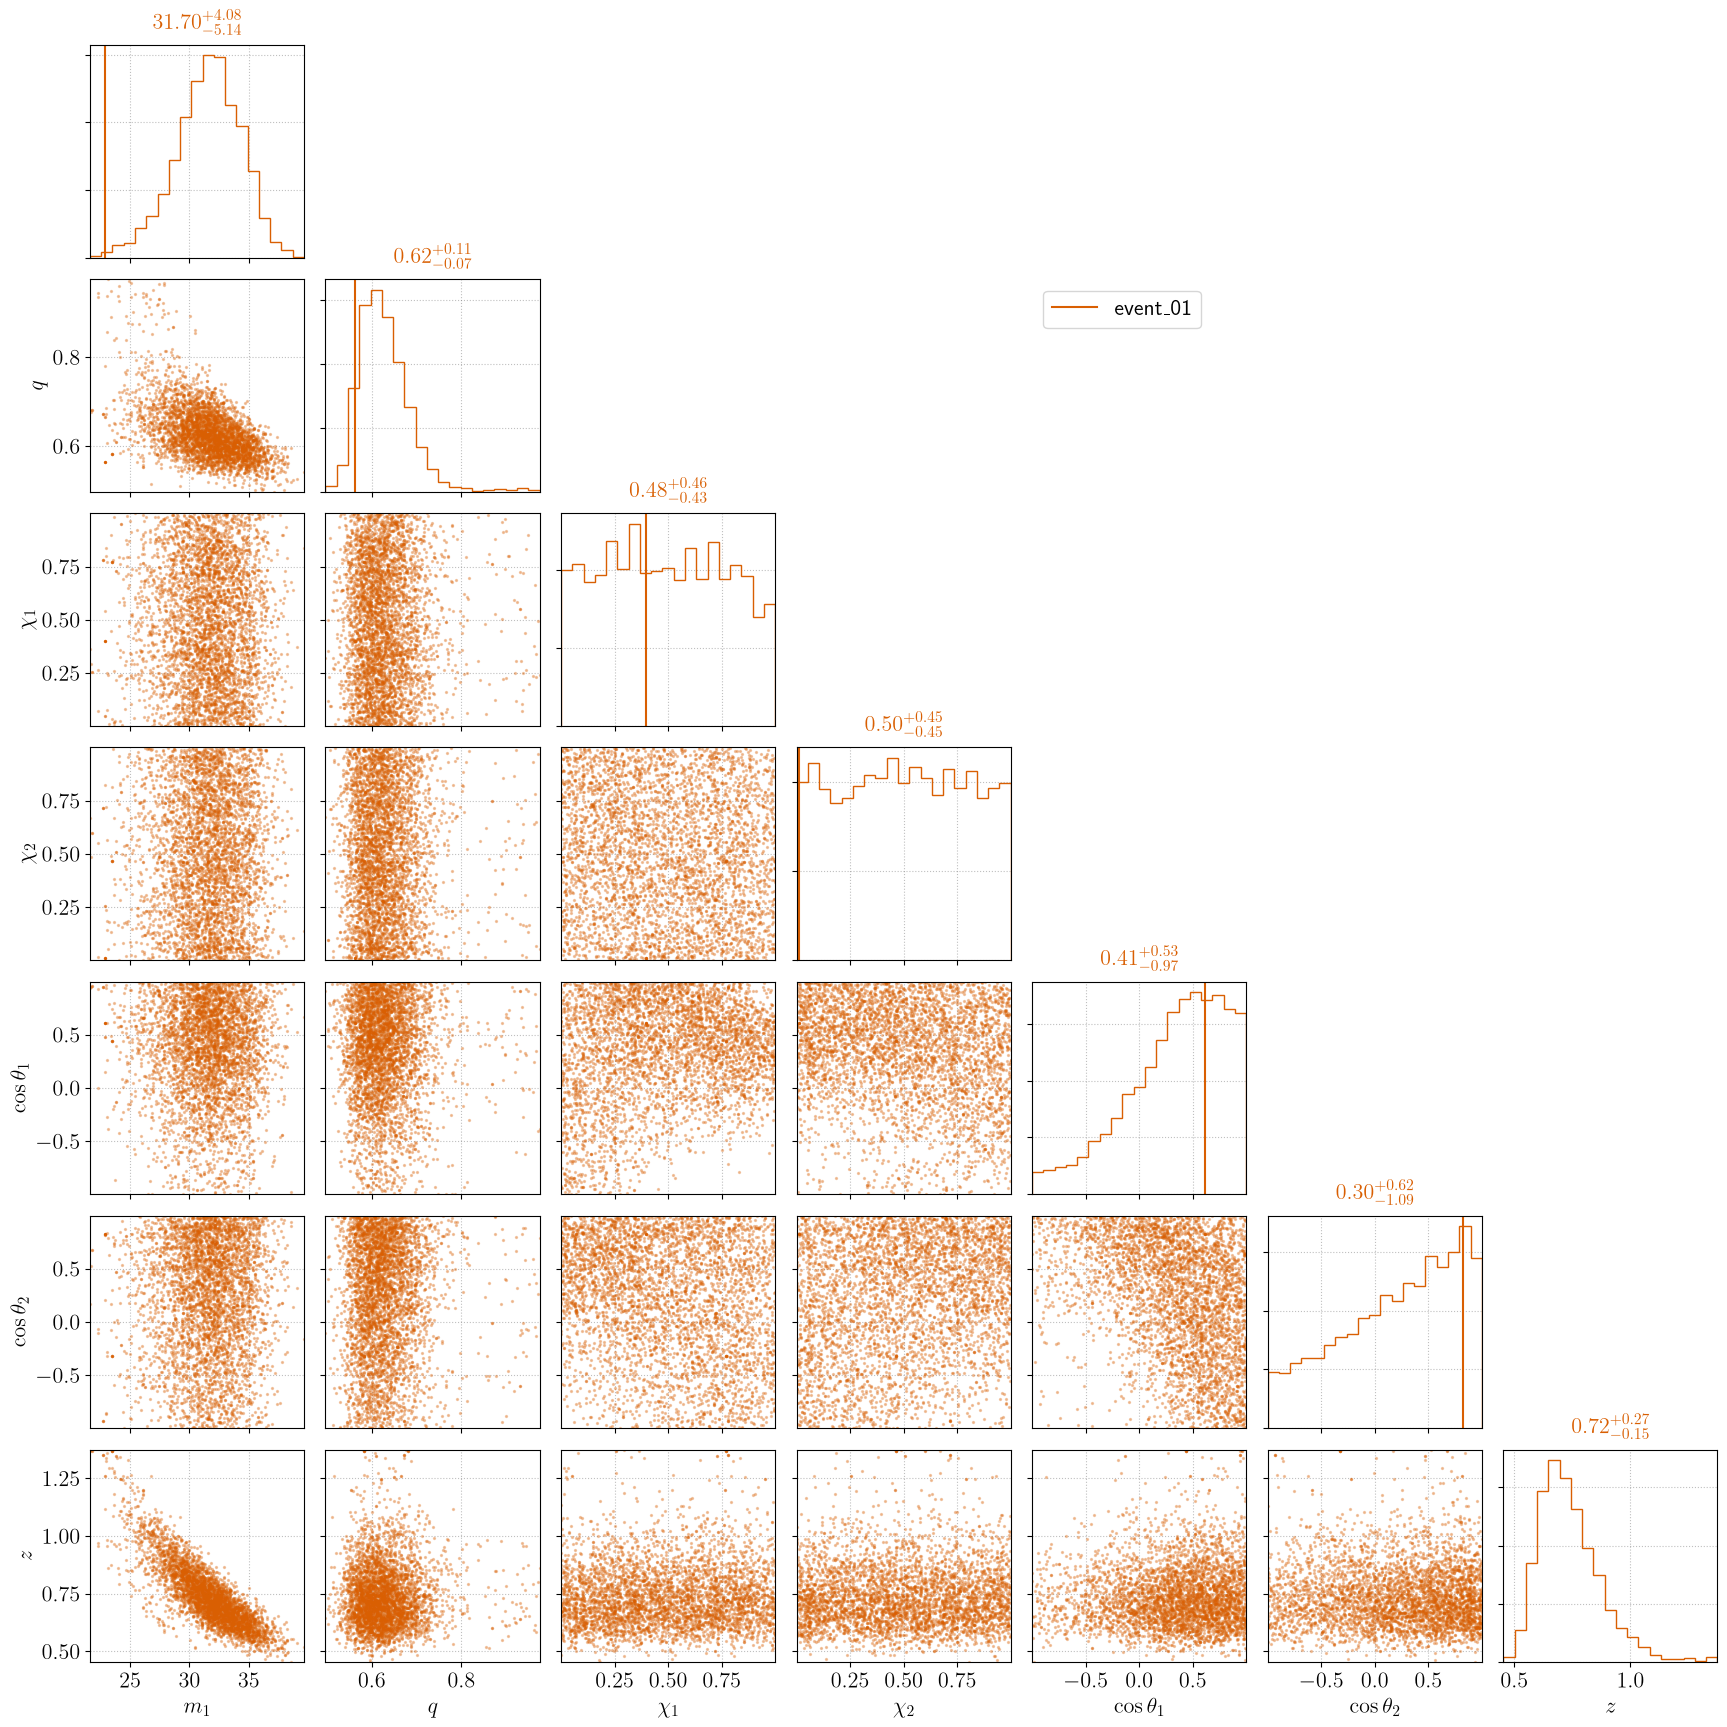

In [12]:
_posterior = catalog.posterior(event.value)
_variables = ["mass_1_source", "mass_ratio", "chi_1", "chi_2", "cos_tilt_1", "cos_tilt_2", "redshift"]
_frame = pd.DataFrame({k: np.asarray(v) for k, v in _posterior.variables(_variables).items()})
_truth = _posterior.metadata["injected_true"]
_fig, _ = ph.make_corner_plot([_frame], model_labels=[event.value], variables=_variables,
                              variable_labels=[LABELS[v] for v in _variables],
                              truth={v: _truth[v] for v in _variables},
                              scatter_kwargs=dict(s=2, alpha=0.3))
mo.vstack([_posterior, _fig])

## The raw data product

`catalog.dataproduct()` resamples every event to the same number of draws. It returns the
exported columns and the PE prior density of those columns only, each with shape
`(events, draws)`:

In [13]:
raw_product = catalog.dataproduct(N=1000)
{k: v.shape for k, v in raw_product.items()}

{'mass_1_source': (20, 1000),
 'mass_ratio': (20, 1000),
 'chi_1': (20, 1000),
 'chi_2': (20, 1000),
 'cos_tilt_1': (20, 1000),
 'cos_tilt_2': (20, 1000),
 'redshift': (20, 1000),
 'prior': (20, 1000)}

## Injections

The selection function is estimated from injections. They are drawn from a broad distribution
$g$, another structured distribution over `GWParams` with fixed parameters and no conditions.
It is flatter than the true population in $m_1$ and $z$, uniform in $q$ and the spins, and
covers the population's support. Each injection is measured once and passed through the same
trigger. `trigger.injections` takes a table of draws and returns it with the measured data,
the detection statistic and whether each injection was detected. The density of $g$ goes in
the `prior` column.

In [14]:
injection_population = GWParams.distribution(
    mass_1_source=PowerLaw(-1.5, 4.0, 120.0),
    mass_ratio=dist.Uniform(0.05, 1.0),
    redshift=PowerLawRedshift(1.0, z_max=Z_MAX),
    projection_factor=ProjectionFactor(),
    chi_1=dist.Uniform(0.0, 1.0),
    chi_2=dist.Uniform(0.0, 1.0),
    cos_tilt_1=dist.Uniform(-1.0, 1.0),
    cos_tilt_2=dist.Uniform(-1.0, 1.0),
)
_draws = injection_population.sample(key=4, N=100_000)
_table = as_table(_draws)
_table["prior"] = np.exp(np.asarray(injection_population.logpdf(_draws)))
injections = trigger.injections(measurement, _table, np.random.default_rng(5))
mo.vstack([injection_population,
           mo.md(f"{injections.detected.sum():,} of {len(injections):,} injections are detected "
                 f"({injections.detected.mean():.2%})."),
           injections[injections.detected].head()])

order,"mass_1_source, mass_ratio, redshift, projection_factor, chi_1, chi_2, cos_tilt_1, cos_tilt_2"


,mass_1_source,mass_ratio,redshift,projection_factor,chi_1,chi_2,cos_tilt_1,cos_tilt_2,prior,mass_2_source,...,chi_p,observed_snr,observed_log_chirp_mass_det,observed_symmetric_mass_ratio,observed_projection_factor_obs,observed_chi_eff,observed_chi_p,selection_statistic,detection_probability,detected
40,10.883572,0.389322,0.266713,0.768229,0.581985,0.454094,-0.341406,0.281754,0.000269,4.237214,...,0.547017,5.588752,2.035543,0.202116,0.781352,-0.082543,0.166353,5.588752,1.0,True
54,62.086326,0.448492,0.660374,0.440503,0.904473,0.284711,-0.675909,0.211864,0.000625,27.845226,...,0.666583,6.264981,4.076200,0.214657,0.417169,-0.382281,0.056377,6.264981,1.0,True
68,65.320212,0.942630,0.468961,0.239325,0.905610,0.422487,0.364925,-0.989600,0.000497,61.572760,...,0.843156,6.084803,4.385023,0.246676,0.176397,0.149212,0.892177,6.084803,1.0,True
73,57.754802,0.662745,0.575572,0.526790,0.998435,0.459185,0.535372,-0.526362,0.000422,38.276697,...,0.843294,7.867467,4.172923,0.241660,0.523813,0.247718,0.051411,7.867467,1.0,True
88,15.751694,0.938363,0.346618,0.670397,0.352594,0.143689,-0.207390,0.075398,0.000600,14.780801,...,0.344928,7.122496,2.884057,0.247407,0.645425,0.164967,0.251359,7.122496,1.0,True
